# BT5340 Assignment 2 Code | Team Perutz

BT5340: Protein Folding and Stability Jan-May 2026<br>
Assignment 2
Group: Perutz (Muhammad, Saahas, Karthik) <br>
File: Prot1.dat  — 45-residue alpha protein, GuHCl denaturant, T = 298 K

Theory:
  Two-state folding: U  ⇌  F
  Rate constants depend on denaturant [D]:
      kf([D]) = kf_water * exp(mf * [D] / RT)   (mf < 0 → kf decreases)
      ku([D]) = ku_water * exp(mu * [D] / RT)   (mu > 0 → ku increases)
  Observed rate:  kobs = kf + ku
  Equilibrium:    Keq([D]) = kf([D]) / ku([D])
  Fraction unfolded: Pu = 1 / (1 + Keq)

Phi-value (protein engineering / Fersht approach):
      φ = ln(kf_mut / kf_WT) / ln(Keq_mut / Keq_WT)
      φ = 0  →  TS is unfolded-like (mutation not felt in TS)
      φ = 1  →  TS is native-like  (mutation fully felt in TS)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
from scipy.interpolate import CubicSpline

# Data loading and formatting

In [47]:
#constants & amino acids:
R_kJ = 8.314e-3 #in kJ/(mol*K)

AA_LIST = ['G','A','V','L','I','M','F','Y','W','S','D','N','T','E','Q','H','K','R','P','C','nV','abu','Tle','CF3-L']
aa_dict = {i+1: AA_LIST[i] for i in range(len(AA_LIST))}
aa_dict[0] = 'WT'

data = np.loadtxt('Prot1.dat')

#column mapping
C_IDX, C_NRES, C_CLASS, C_TEMP, C_DEN, C_FROM, C_TO, C_RES, C_MF, C_MU, C_KF, C_KU = 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
prot_classes = {1:'α', 2:'β', 4:'α/β'}
denaturants = {0:'Urea', 1:'GuHCl'}

wt = data[0]
mutants = data[1:]

T = wt[C_TEMP] #at 298 K
RT = R_kJ * T #2.4776 kJ/mol
n_mut = len(mutants)
den_name = denaturants[int(wt[C_DEN])]
prot_class = prot_classes[int(wt[C_CLASS])]

#wild type (WT) parameters:
mf_wt = wt[C_MF]
mu_wt = wt[C_MU]
kf_wt = wt[C_KF]
ku_wt = wt[C_KU]
Keq_wt_0 = kf_wt / ku_wt #Keq at [D]=0

#Mutant lables
def make_label(row):
    fa = aa_dict.get(int(row[C_FROM]), '?')
    ta = aa_dict.get(int(row[C_TO]), '?')
    return f"{fa}{int(row[C_RES])}{ta}"

mut_labels = [make_label(r) for r in mutants]

print(f"Protein: {int(wt[C_NRES])}-residue {prot_class} protein")
print(f"Denaturant: {den_name}; T = {T:.0f} K;  RT = {RT:.4f} kJ/mol")
print(f"WT parameters: mf = {mf_wt:.4f} kJ/(mol·M), mu = {mu_wt:.4f} kJ/(mol·M), kf_w = {kf_wt:.0f} s⁻¹  ku_w = {ku_wt:.0f} s⁻¹")
print(f"Keq(0M) = {Keq_wt_0:.1f}")

ΔGu_wt = RT * np.log(Keq_wt_0)
print(f"ΔGu(0M) = {ΔGu_wt:.2f} kJ/mol")

Dm_wt = RT * np.log(kf_wt / ku_wt) / (mu_wt - mf_wt)
print(f"[D]_m(WT) = {Dm_wt:.4f} M {den_name}")
print(f"Total mutants: {n_mut}")

Protein: 45-residue α protein
Denaturant: GuHCl; T = 298 K;  RT = 2.4776 kJ/mol
WT parameters: mf = -2.3012 kJ/(mol·M), mu = 1.2552 kJ/(mol·M), kf_w = 27600 s⁻¹  ku_w = 20 s⁻¹
Keq(0M) = 1380.0
ΔGu(0M) = 17.91 kJ/mol
[D]_m(WT) = 5.0367 M GuHCl
Total mutants: 22


# Q1

Chevron plots of all mutants in a single graph as a function of the denaturant concentration

/tmp/ipykernel_26446/3606257395.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', n_mut) #different colors


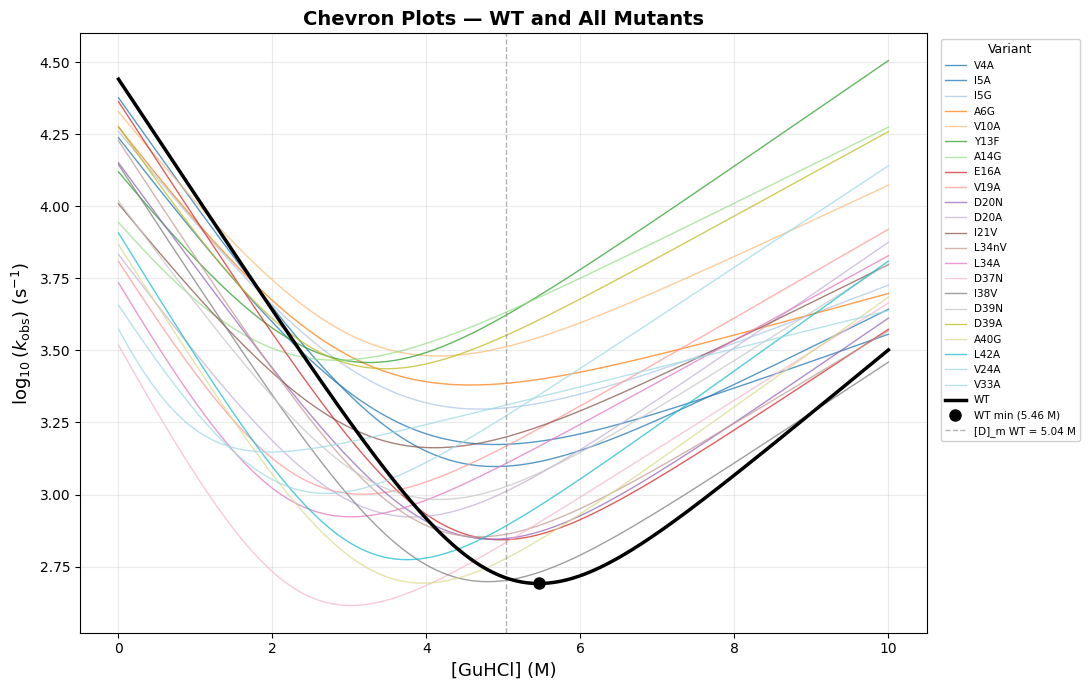

In [5]:
#log10(kobs)= log10[ kf_w*exp(mf*[D]/RT) + ku_w*exp(mu*[D]/RT)]

D_plot = np.linspace(0.0, 10.0, 400) #0 to 10 M GuHCl, range that was mentioned in class

def kobs_of_D(row, D):
    kf = row[C_KF] * np.exp(row[C_MF] * D / RT)
    ku = row[C_KU] * np.exp(row[C_MU] * D / RT)
    return kf + ku

cmap = cm.get_cmap('tab20', n_mut) #different colors
colors = [cmap(i) for i in range(n_mut)]

fig1, ax1 = plt.subplots(figsize=(11, 7))

for i, (row, color, label) in enumerate(zip(mutants, colors, mut_labels)):
    kobs_i = kobs_of_D(row, D_plot)
    ax1.plot(D_plot, np.log10(kobs_i), '-', color=color,
             linewidth=1.0, alpha=0.75, label=label)

#WT on top in black
kobs_wt_plot = kobs_of_D(wt, D_plot)
ax1.plot(D_plot, np.log10(kobs_wt_plot), 'k-', linewidth=2.5, label='WT', zorder=10)

#dkobs/dD = 0; mf*kf([D]) + mu*ku([D]) = 0; then Keq([D_min]) = mu/|mf|
#so D_min = RT*ln(mu*ku_w / (|mf|*kf_w)) / (mf − mu)

D_min_wt = RT * np.log(mu_wt * ku_wt / ((-mf_wt) * kf_wt)) / (mf_wt - mu_wt)

if 0 < D_min_wt < 10:
    kobs_min = kobs_of_D(wt, np.array([D_min_wt]))[0]
    ax1.plot(D_min_wt, np.log10(kobs_min), 'ko', ms=8, zorder=11, label=f'WT min ({D_min_wt:.2f} M)')

ax1.axvline(Dm_wt, color='gray', linestyle='--', linewidth=1, alpha=0.6, label=f'[D]_m WT = {Dm_wt:.2f} M')
ax1.set_xlabel(f'[{den_name}] (M)', fontsize=13)
ax1.set_ylabel(r'$\log_{10}(k_\mathrm{obs})\ (\mathrm{s}^{-1})$', fontsize=13)
ax1.set_title('Chevron Plots — WT and All Mutants', fontsize=14, fontweight='bold')
ax1.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7.5, ncol=1, framealpha=0.9, title='Variant', title_fontsize=9)
ax1.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig('Q1_chevron_plots.png', dpi=150, bbox_inches='tight')
plt.show()

#Q2

Phi-values at 0 M denaturant

Phi-values at 0 M denaturant:
      Mut  Res   kf_mut  ku_mut      ΔΔG‡      ΔΔGeq     φ(0M)
0     V4A    4  23600.0   210.0  0.387911   6.213613  0.062429
1     I5A    5  16900.0   400.0  1.215254   8.637397  0.140697
2     I5G    5  17700.0   500.0  1.100664   9.075661  0.121276
3     A6G    6  17900.0   920.0  1.072826  10.558561  0.101607
4    V10A   10  20600.0   670.0  0.724751   9.424858  0.076898
5    Y13F   13  12700.0   470.0  1.923126   9.744821  0.197348
6    A14G   14   7900.0   900.0  3.099326  12.530607  0.247340
7    E16A   16  23000.0    65.0  0.451715   3.371917  0.133964
8    V19A   19   6200.0   240.0  3.699675   9.856210  0.375365
9    D20N   20  14100.0    60.0  1.664039   4.385930  0.379404
10   D20A   20   6700.0   110.0  3.507519   7.731155  0.453686
11   I21V   21   9900.0   300.0  2.540208   9.249597  0.274629
12  L34nV   34  16800.0    90.0  1.229958   4.956418  0.248155
13   L34A   34   5200.0   230.0  4.135457  10.186548  0.405972
14   D37N   37   3200.0  

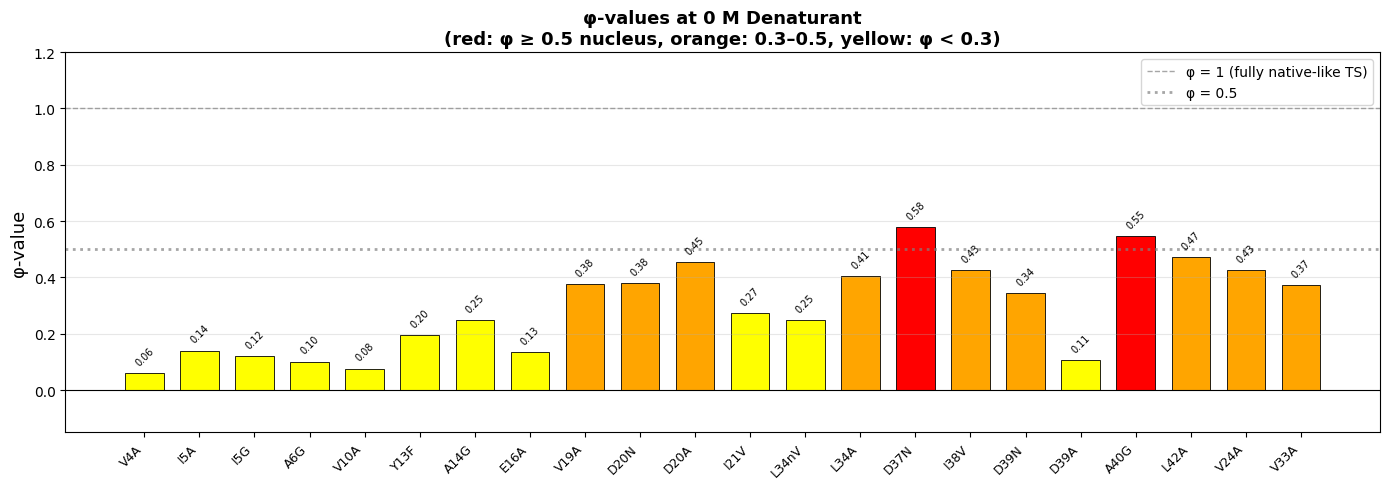

In [51]:
#ΔΔGTS = RT*ln(kf_WT / kf_mut) [activation free energy change]
#ΔΔGeq = RT*ln(Keq_WT / Keq_mut) [equilibrium free energy change]
#φ = ΔΔGTS/ΔΔGeq = ln(kf_mut/kf_WT) / ln(Keq_mut/Keq_WT)

def phi_value(kf_mut, ku_mut, kf_ref, ku_ref):
    Keq_ref = kf_ref / ku_ref
    Keq_mut = kf_mut / ku_mut
    num = np.log(kf_mut / kf_ref)
    den = np.log(Keq_mut / Keq_ref)
    if abs(den) < 1e-12:
        return np.nan
    return num / den

phi_0 = np.array([phi_value(r[C_KF], r[C_KU], kf_wt, ku_wt) for r in mutants])
ΔΔGTS_0 = np.array([RT * np.log(kf_wt / r[C_KF]) for r in mutants])
ΔΔGeq_0 = np.array([RT * np.log(Keq_wt_0 / (r[C_KF]/r[C_KU])) for r in mutants])

df_phi_0 = pd.DataFrame({
    "Mut": mut_labels,
    "Res": [int(r[C_RES]) for r in mutants],
    "kf_mut": [r[C_KF] for r in mutants],
    "ku_mut": [r[C_KU] for r in mutants],
    "ΔΔG‡": ΔΔGTS_0,
    "ΔΔGeq": ΔΔGeq_0,
    "φ(0M)": phi_0
})

print("Phi-values at 0 M denaturant:")
print(df_phi_0)

high_phi_0 = [(mut_labels[i], int(mutants[i][C_RES]), phi_0[i]) for i in range(n_mut) if not np.isnan(phi_0[i]) and phi_0[i] >= 0.4]
high_phi_0.sort(key=lambda x: -x[2]) #decreasing phi order
print(f"\nPutative folding nucleus residues (φ ≥ 0.4 at 0 M):") #0.4 being our threshold
for label, res, phi in high_phi_0:
    print(f"{label}: φ = {phi:.3f}")

#bar chart φ(at 0 M)
fig2, ax2 = plt.subplots(figsize=(14, 5))
x_pos = np.arange(n_mut)
bar_colors = []
for phi in phi_0:
    if np.isnan(phi):bar_colors.append('lightgray')
    elif phi >= 0.5:bar_colors.append('red') #high - likely nucleus
    elif phi >= 0.3:bar_colors.append('orange') #medium
    else:bar_colors.append('yellow') #low

bars = ax2.bar(x_pos, phi_0, color=bar_colors, edgecolor='black', linewidth=0.6, width=0.7)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.axhline(1.0, color='gray', linewidth=1.0, linestyle='--', alpha=0.7, label='φ = 1 (fully native-like TS)')
ax2.axhline(0.5, color='gray', linewidth=2, linestyle=':', alpha=0.7, label='φ = 0.5')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(mut_labels, rotation=45, ha='right', fontsize=9)
ax2.set_ylabel('φ-value', fontsize=13)
ax2.set_title('φ-values at 0 M Denaturant\n(red: φ ≥ 0.5 nucleus, orange: 0.3–0.5, yellow: φ < 0.3)', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.set_ylim(-0.15, 1.2)
ax2.grid(True, axis='y', alpha=0.3)

for bar, phi in zip(bars, phi_0):
    if not np.isnan(phi):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{phi:.2f}', ha='center', va='bottom', fontsize=7, rotation=45)

plt.tight_layout()
plt.savefig('Q2_phi_0M.png', dpi=150, bbox_inches='tight')
plt.show()

# Q3

Phi-values at WT midpoint [D]_m


Phi-values at 0 M denaturant
      Mut  Res   kf_mut  ku_mut      ΔΔG‡      ΔΔGeq     φ(0M)
0     V4A    4  23600.0   210.0  0.387911   6.213613  0.062429
1     I5A    5  16900.0   400.0  1.215254   8.637397  0.140697
2     I5G    5  17700.0   500.0  1.100664   9.075661  0.121276
3     A6G    6  17900.0   920.0  1.072826  10.558561  0.101607
4    V10A   10  20600.0   670.0  0.724751   9.424858  0.076898
5    Y13F   13  12700.0   470.0  1.923126   9.744821  0.197348
6    A14G   14   7900.0   900.0  3.099326  12.530607  0.247340
7    E16A   16  23000.0    65.0  0.451715   3.371917  0.133964
8    V19A   19   6200.0   240.0  3.699675   9.856210  0.375365
9    D20N   20  14100.0    60.0  1.664039   4.385930  0.379404
10   D20A   20   6700.0   110.0  3.507519   7.731155  0.453686
11   I21V   21   9900.0   300.0  2.540208   9.249597  0.274629
12  L34nV   34  16800.0    90.0  1.229958   4.956418  0.248155
13   L34A   34   5200.0   230.0  4.135457  10.186548  0.405972
14   D37N   37   3200.0  

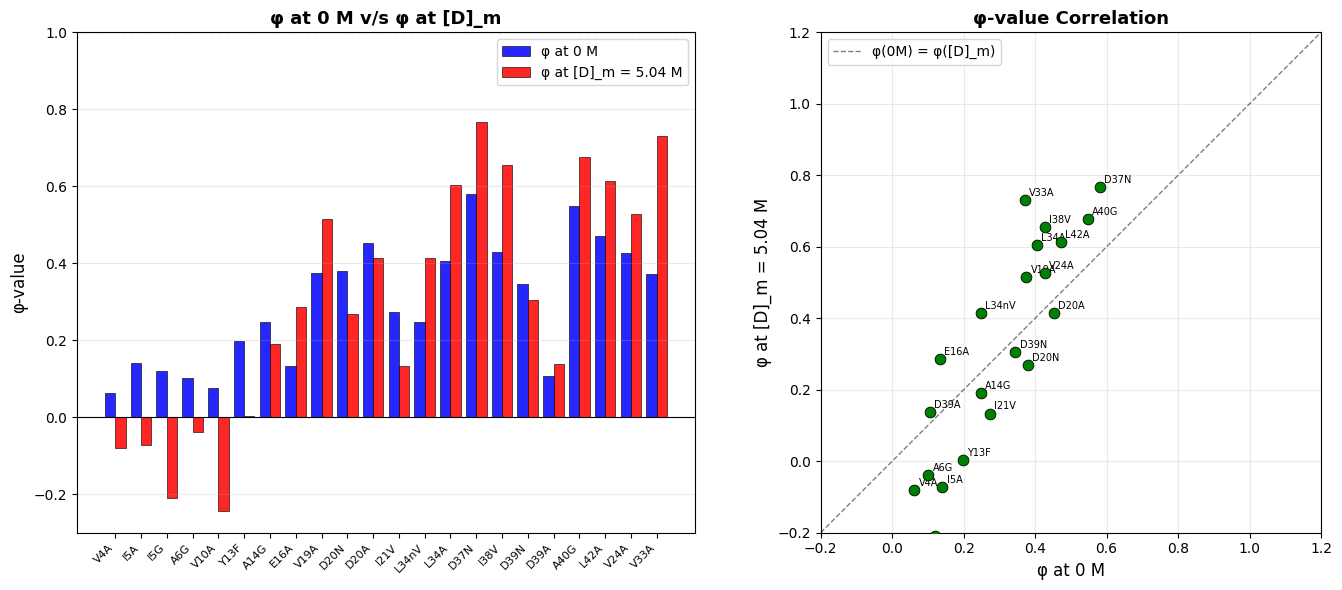

In [53]:
#At [D]_m:  kf_WT([D]_m) = ku_WT([D]_m) → Keq_WT([D]_m) = 1
#Adjusted rates:
#kf_i([D]_m) = kf_i_water · exp(mf_i · [D]_m / RT)
#ku_i([D]_m) = ku_i_water · exp(mu_i · [D]_m / RT)
#so φ_m = ln(kf_i([D]_m)/kf_WT([D]_m)) / ln(Keq_i([D]_m))

kf_wt_m = kf_wt * np.exp(mf_wt * Dm_wt / RT)
ku_wt_m = ku_wt * np.exp(mu_wt * Dm_wt / RT)

phi_m = np.zeros(n_mut)
ΔΔGTS_m = np.zeros(n_mut)
ΔΔGeq_m = np.zeros(n_mut)

for i, row in enumerate(mutants):
    kf_im = row[C_KF] * np.exp(row[C_MF] * Dm_wt / RT)
    ku_im = row[C_KU] * np.exp(row[C_MU] * Dm_wt / RT)
    phi_m[i] = phi_value(kf_im, ku_im, kf_wt_m, ku_wt_m)
    ΔΔGTS_m[i] = RT * np.log(kf_wt_m / kf_im)
    ΔΔGeq_m[i] = RT * np.log(1.0 / (kf_im / ku_im)) #Keq_WT_m = 1


df_phi_0 = pd.DataFrame({
    "Mut": mut_labels,
    "Res": [int(r[C_RES]) for r in mutants],
    "kf_mut": [r[C_KF] for r in mutants],
    "ku_mut": [r[C_KU] for r in mutants],
    "ΔΔG‡": ΔΔGTS_0,
    "ΔΔGeq": ΔΔGeq_0,
    "φ(0M)": phi_0
})

print("\nPhi-values at 0 M denaturant")
print(df_phi_0)

#scatter plot: φ(0M) vs φ([D]m)
fig3, axes3 = plt.subplots(1, 2, figsize=(14, 6))

#panel A: grouped bar
x_pos = np.arange(n_mut)
w = 0.4 #bar width
axes3[0].bar(x_pos - w/2, phi_0, w, label=f'φ at 0 M', color='blue', edgecolor='black', linewidth=0.5, alpha=0.85)
axes3[0].bar(x_pos + w/2, phi_m, w, label=f'φ at [D]_m = {Dm_wt:.2f} M', color='red', edgecolor='black', linewidth=0.5, alpha=0.85)
axes3[0].axhline(0, color='black', linewidth=0.8)
axes3[0].axhline(1.0, color='gray', linewidth=1, linestyle='--', alpha=0.6)
axes3[0].set_xticks(x_pos)
axes3[0].set_xticklabels(mut_labels, rotation=45, ha='right', fontsize=8)
axes3[0].set_ylabel('φ-value', fontsize=12)
axes3[0].set_title('φ at 0 M v/s φ at [D]_m', fontsize=13, fontweight='bold')
axes3[0].legend(fontsize=10)
axes3[0].set_ylim(-0.3, 1)
axes3[0].grid(True, axis='y', alpha=0.25)

#panel B: correlation scatter
x_vals = []
y_vals = []
labels = []

for i in range(n_mut):
    if not np.isnan(phi_0[i]) and not np.isnan(phi_m[i]):
        x_vals.append(phi_0[i])
        y_vals.append(phi_m[i])
        labels.append(mut_labels[i])

axes3[1].scatter(x_vals, y_vals, s=60, c='green', edgecolors='black', linewidths=0.6, zorder=5)

for x, y, label in zip(x_vals, y_vals, labels):
    axes3[1].annotate(label, (x, y), fontsize=7, xytext=(3, 3), textcoords='offset points')

lim = (-0.2, 1.2) #diagonal reference line
axes3[1].plot(lim, lim, 'k--', linewidth=1.0, alpha=0.5, label='φ(0M) = φ([D]_m)')

axes3[1].set_xlim(*lim)
axes3[1].set_ylim(*lim)
axes3[1].set_xlabel('φ at 0 M', fontsize=12)
axes3[1].set_ylabel(f'φ at [D]_m = {Dm_wt:.2f} M', fontsize=12)
axes3[1].set_title('φ-value Correlation', fontsize=13, fontweight='bold')
axes3[1].legend(fontsize=10)
axes3[1].grid(True, alpha=0.25)
axes3[1].set_aspect('equal')

plt.tight_layout()
plt.savefig('Q3_phi_midpoint.png', dpi=150, bbox_inches='tight')
plt.show()

# Q4

Equilibrium chemical denaturation curves

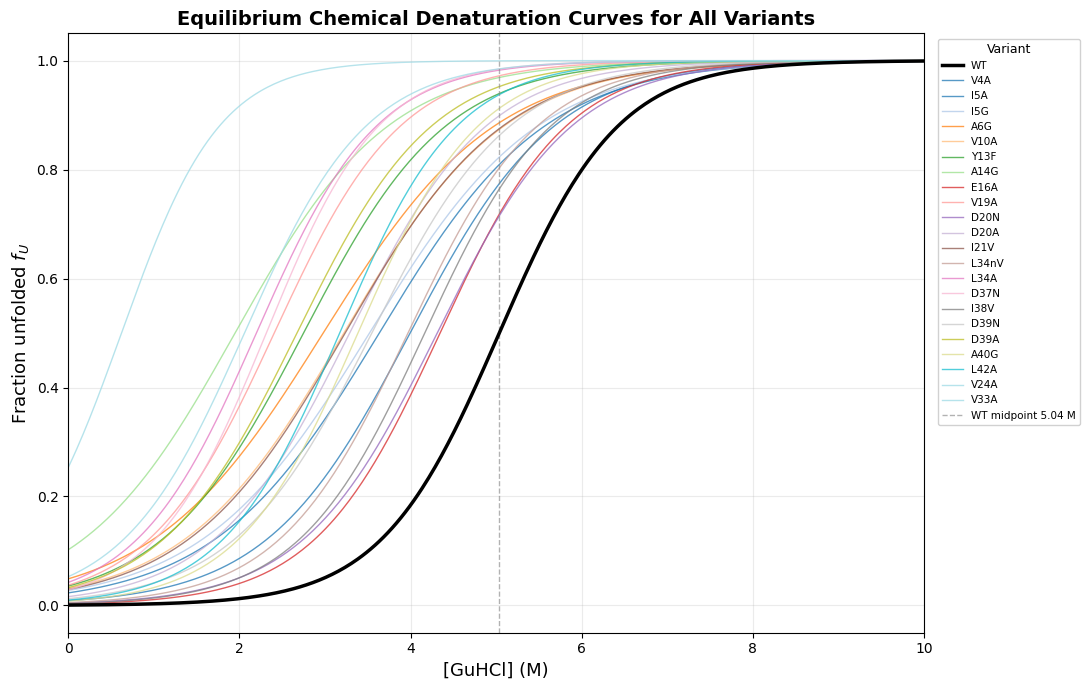

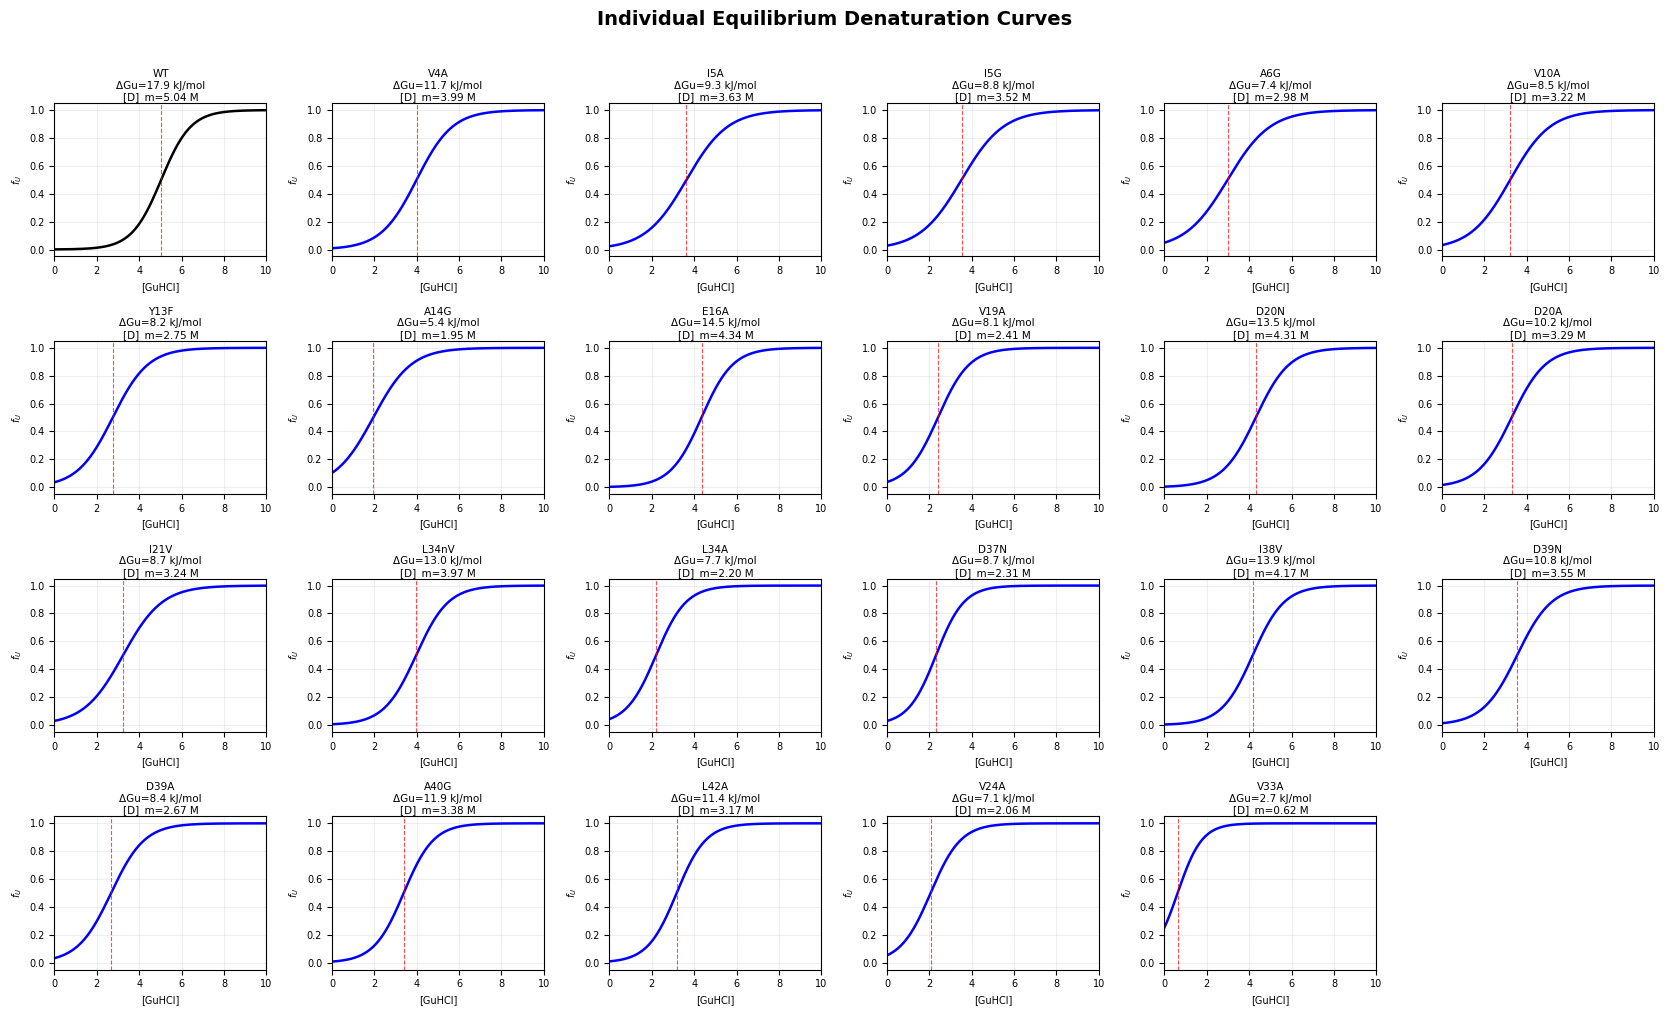

   Variant  ΔGu (kJ/mol)  [D]_m (M)  m-value
0       WT     17.912446   5.036679  3.55640
1      V4A     11.698834   3.994412  2.92880
2      I5A      9.275049   3.634082  2.55224
3      I5G      8.836785   3.520071  2.51040
4      A6G      7.353885   2.979018  2.46856
5     V10A      8.487588   3.219972  2.63592
6     Y13F      8.167625   2.749450  2.97064
7     A14G      5.381840   1.948925  2.76144
8     E16A     14.540529   4.344087  3.34720
9     V19A      8.056236   2.406858  3.34720
10    D20N     13.526516   4.310553  3.13800
11    D20A     10.181291   3.288361  3.09616
12    I21V      8.662849   3.235110  2.67776
13   L34nV     12.956028   3.969955  3.26352
14    L34A      7.725898   2.198255  3.51456
15    D37N      8.713693   2.314025  3.76560
16    I38V     13.942836   4.165522  3.34720
17    D39N     10.832848   3.546730  3.05432
18    D39A      8.386425   2.672538  3.13800
19    A40G     11.895529   3.384643  3.51456
20    L42A     11.409641   3.170895  3.59824
21    V24A

In [54]:
#Keq([D]) = kf([D]) / ku([D]) = (kf_w/ku_w) · exp((mf − mu)·[D]/RT)
#ΔGu([D]) = RT·ln(Keq)  = ΔGu(0) + (mf − mu)·[D]
#fu([D])  = 1 / (1 + Keq([D]))

def fu_curve(row, D): #fraction unfolded as a function of denaturant concentration
    Keq = (row[C_KF] / row[C_KU]) * np.exp((row[C_MF] - row[C_MU]) * D / RT)
    return 1.0 / (1.0 + Keq)

all_rows = np.vstack([wt.reshape(1,-1), mutants])
all_labels = ['WT'] + mut_labels

#Overlay plot
fig4a, ax4a = plt.subplots(figsize=(11, 7))
fu_wt_plot = fu_curve(wt, D_plot)
ax4a.plot(D_plot, fu_wt_plot, 'k-', linewidth=2.5, label='WT', zorder=10)
for i, (row, color, label) in enumerate(zip(mutants, colors, mut_labels)):
    fu_i = fu_curve(row, D_plot)
    ax4a.plot(D_plot, fu_i, '-', color=color, linewidth=1.0, alpha=0.75, label=label)

ax4a.axvline(Dm_wt, color='gray', linestyle='--', linewidth=1, alpha=0.6, label=f'WT midpoint {Dm_wt:.2f} M')
ax4a.set_xlabel(f'[{den_name}] (M)', fontsize=13)
ax4a.set_ylabel('Fraction unfolded $f_U$', fontsize=13)
ax4a.set_title('Equilibrium Chemical Denaturation Curves for All Variants', fontsize=14, fontweight='bold')
ax4a.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7.5, ncol=1, framealpha=0.9, title='Variant', title_fontsize=9)
ax4a.set_xlim(0, 10)
ax4a.set_ylim(-0.05, 1.05)
ax4a.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig('Q4_equilibrium_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

#individual subplots grid
ncols = 6
nrows = int(np.ceil((n_mut + 1) / ncols))
fig4b, axes4b = plt.subplots(nrows, ncols, figsize=(ncols*2.8, nrows*2.5))
axes4b_flat = axes4b.flatten()
for idx, (row, label) in enumerate(zip(all_rows, all_labels)):
    ax = axes4b_flat[idx]
    fu_i = fu_curve(row, D_plot)
    #computing this variant's midpoint
    Dm_i = RT * np.log(row[C_KF]/row[C_KU]) / (row[C_MU] - row[C_MF])
    clr = 'black' if label == 'WT' else 'blue'
    ax.plot(D_plot, fu_i, color=clr, linewidth=1.8)
    ax.axvline(Dm_i, color='red', linestyle='--', linewidth=0.8, alpha=0.7)

    #stability annotation
    ΔGu_i = RT * np.log(row[C_KF]/row[C_KU])
    ax.set_title(f'{label}\nΔGu={ΔGu_i:.1f} kJ/mol\n[D]_m={Dm_i:.2f} M', fontsize=7.5, pad=2)
    ax.set_xlim(0, 10); ax.set_ylim(-0.05, 1.05)
    ax.tick_params(labelsize=7)
    ax.set_xlabel(f'[{den_name}]', fontsize=7)
    ax.set_ylabel('$f_U$', fontsize=7)
    ax.grid(True, alpha=0.2)

for idx in range(len(all_rows), len(axes4b_flat)):
    axes4b_flat[idx].set_visible(False) #making sure the last empty plot doesnt appear

fig4b.suptitle('Individual Equilibrium Denaturation Curves', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('Q4_equilibrium_individual.png', dpi=150, bbox_inches='tight')
plt.show()

data = []

for row, label in zip(all_rows, all_labels):
    ΔGu_i = RT * np.log(row[C_KF] / row[C_KU])
    Dm_i  = RT * np.log(row[C_KF] / row[C_KU]) / (row[C_MU] - row[C_MF])
    m_i   = row[C_MU] - row[C_MF]
    data.append([label, ΔGu_i, Dm_i, m_i])

df = pd.DataFrame(data, columns=["Variant", "ΔGu (kJ/mol)", "[D]_m (M)", "m-value"])

print(df)

/tmp/ipykernel_5796/4181314367.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


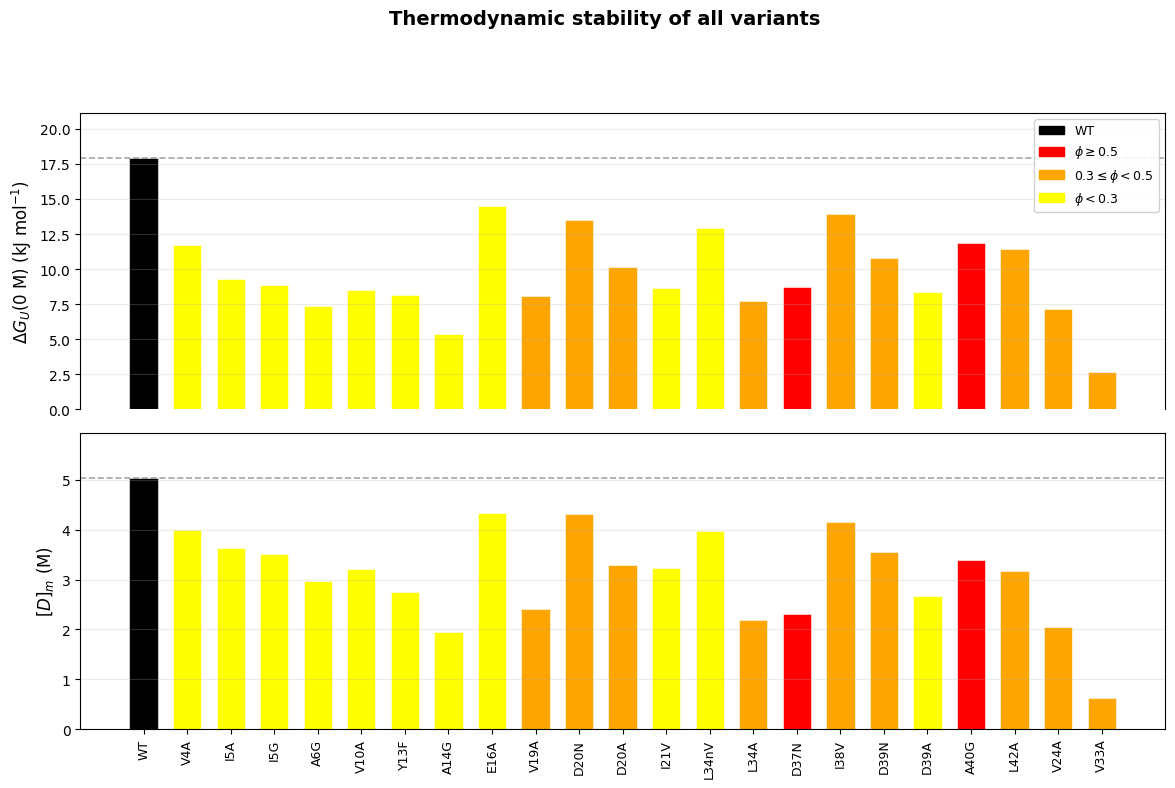

In [ ]:
def phi_color(label): #gets bar colour for a variant based on its φ-value
    if label == 'WT':
        return 'black'
    phi = phi_0[label] if isinstance(phi_0, dict) else phi_0[mut_labels.index(label)]
    if phi >= 0.5:
        return 'red'
    elif phi >= 0.3:
        return 'orange'
    else:
        return 'yellow'

bar_labels = ['WT'] + mut_labels
bar_colors = [phi_color(lbl) for lbl in bar_labels]

dGu_vals = []
Dm_vals = []
for row in np.vstack([wt.reshape(1, -1), mutants]):
    dGu = RT * np.log(row[C_KF] / row[C_KU])
    Dm = dGu / (row[C_MU] - row[C_MF])
    dGu_vals.append(dGu)
    Dm_vals.append(Dm)

x = np.arange(len(bar_labels))
bar_width = 0.65

fig_bar, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'hspace': 0.08})

ax_top.bar(x, dGu_vals, width=bar_width, color=bar_colors, edgecolor='white', linewidth=0.4)
ax_top.axhline(dGu_vals[0], color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
ax_top.set_ylabel(r'$\Delta G_U$(0 M) (kJ mol$^{-1}$)', fontsize=12)
ax_top.set_ylim(0, max(dGu_vals) * 1.18)
ax_top.grid(axis='y', alpha=0.25)
ax_top.tick_params(axis='x', bottom=False)
ax_top.spines['bottom'].set_visible(False)

ax_bot.bar(x, Dm_vals, width=bar_width, color=bar_colors, edgecolor='white', linewidth=0.4)
ax_bot.axhline(Dm_vals[0], color='gray', linestyle='--', linewidth=1.2, alpha=0.7)
ax_bot.set_ylabel(r'$[D]_m$ (M)', fontsize=12)
ax_bot.set_ylim(0, max(Dm_vals) * 1.18)
ax_bot.grid(axis='y', alpha=0.25)
ax_bot.set_xticks(x)
ax_bot.set_xticklabels(bar_labels, rotation=90, fontsize=9)

legend_handles = [
    mpatches.Patch(color='black', label='WT'),
    mpatches.Patch(color='red', label=r'$\phi \geq 0.5$'),
    mpatches.Patch(color='orange', label=r'$0.3 \leq \phi < 0.5$'),
    mpatches.Patch(color='yellow', label=r'$\phi < 0.3$'),
]

ax_top.legend(handles=legend_handles, fontsize=9, framealpha=0.9, loc='upper right', title_fontsize=9)

fig_bar.suptitle('Thermodynamic stability of all variants', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('Q4_stability_bars.png', dpi=150, bbox_inches='tight')
plt.show()

# Q5

Three-State Folding Model: U ⇌ T S1 ⇌ I ⇌ T S2 ⇌ F

Mechanism
$$
U \leftrightarrow I \leftrightarrow F
$$
$$
K_1 = \frac{[I]}{[U]}, \quad K_2 = \frac{[F]}{[I]}
$$

Rate equations
$$
\frac{d[U]}{dt} = -k_{f1}[U] + k_{u1}[I]
$$
$$
\frac{d[I]}{dt} = k_{f1}[U] - (k_{u1} + k_{f2})[I] + k_{u2}[F]
$$
$$
\frac{d[F]}{dt} = k_{f2}[I] - k_{u2}[F]
$$

Eigenvalues
$$
b = k_{f1} + k_{u1} + k_{f2} + k_{u2}
$$
$$
c = k_{f1}k_{f2} + k_{f1}k_{u2} + k_{u1}k_{u2}
$$
$$
\lambda_{\pm} = \frac{b \pm \sqrt{b^2 - 4c}}{2}
$$

Denaturant dependence
$$
k_{f1} = k_{f1,0} \exp\left(\frac{m_{f1}[D]}{RT}\right), \quad
k_{u1} = k_{u1,0} \exp\left(\frac{m_{u1}[D]}{RT}\right)
$$
$$
k_{f2} = k_{f2,0} \exp\left(\frac{m_{f2}[D]}{RT}\right), \quad
k_{u2} = k_{u2,0} \exp\left(\frac{m_{u2}[D]}{RT}\right)
$$

Equilibrium
$$
K_1 = \frac{k_{f1,0}}{k_{u1,0}} \exp\left(\frac{(m_{f1}-m_{u1})[D]}{RT}\right)
$$
$$
K_2 = \frac{k_{f2,0}}{k_{u2,0}} \exp\left(\frac{(m_{f2}-m_{u2})[D]}{RT}\right)
$$
$$
f_U = \frac{1}{1 + K_1 + K_1 K_2}, \quad
f_I = K_1 f_U, \quad
f_F = K_1 K_2 f_U
$$

Phi-Values
$$
\phi_1 = \frac{\Delta\Delta G_{TS1}}{\Delta\Delta G_{total}}, \quad
\phi_2 = \frac{\Delta\Delta G_{TS2}}{\Delta\Delta G_{total}}
$$

$$
\Delta\Delta G_{TS1} = RT \ln\left(\frac{k_{f1}^{WT}}{k_{f1}^{mut}}\right)
$$

$$
\Delta\Delta G_{TS2} =
RT \ln\left(\frac{k_{f1}^{WT} k_{u1}^{mut}}{k_{f1}^{mut} k_{u1}^{WT}}\right)
+ RT \ln\left(\frac{k_{f2}^{WT}}{k_{f2}^{mut}}\right)
$$

$$
\Delta\Delta G_{total} =
RT \ln\left(\frac{K_{eq1}^{WT} K_{eq2}^{WT}}{K_{eq1}^{mut} K_{eq2}^{mut}}\right)
$$

Final Phis
$$
\phi_{1} = \frac{\ln(k_{f1}^{mut}/k_{f1}^{WT})}{\ln(K_1^{mut}/K_1^{WT})}
$$
$$
\phi_{2} = \frac{\ln(k_{f2}^{mut}/k_{f2}^{WT})}{\ln(K_2^{mut}/K_2^{WT})}
$$


                  Mutant    ΔΔG_UF     φ_TS1     φ_TS2
0  Mut-A (early nucleus)  8.452655  0.878084  0.946559
1   Mut-B (late nucleus)  8.708311  0.029976  0.972884


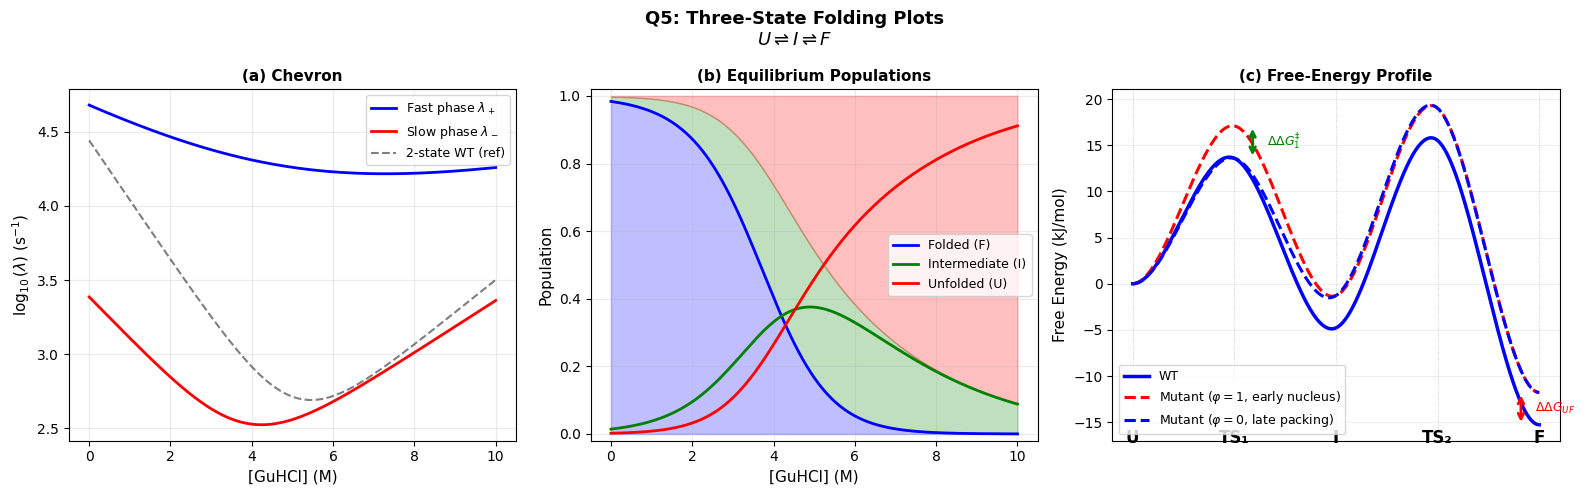

In [48]:
#taking U → I as the fast step, I → F as the slow (rate-limiting) step:
kf1_0 = kf_wt * 1.5 #U→I in water (s⁻¹ for all)
ku1_0 = ku_wt * 300.0 #I→U in water
kf2_0 = kf_wt * 0.1 #I→F in water
ku2_0 = ku_wt * 2.0 #F→I in water

mf1 = mf_wt * 0.35 #m-value split across two barriers, all in kJ/(mol·M)
mu1 = mu_wt * 0.20
mf2 = mf_wt * 0.65
mu2 = mu_wt * 0.80

D_3s = np.linspace(0, 10, 400) #again taking 0 to 10 M

kf1_D = kf1_0 * np.exp(mf1 * D_3s / RT)
ku1_D = ku1_0 * np.exp(mu1 * D_3s / RT)
kf2_D = kf2_0 * np.exp(mf2 * D_3s / RT)
ku2_D = ku2_0 * np.exp(mu2 * D_3s / RT)

#getting the eigenvalues of the rate matrix:
b = kf1_D + ku1_D + kf2_D + ku2_D
c = kf1_D*kf2_D + kf1_D*ku2_D + ku1_D*ku2_D
disc = np.maximum(b**2 - 4*c, 0)
lam_fast = (b + np.sqrt(disc)) / 2.0
lam_slow = (b - np.sqrt(disc)) / 2.0

#equilibrium populations (as done in assignment 1; section 2.2.2):
K1_D = kf1_D / ku1_D
K2_D = kf2_D / ku2_D
Z = 1.0 + K1_D + K1_D * K2_D
P_U = 1.0 / Z
P_I = K1_D / Z
P_F = K1_D * K2_D / Z

#we've plotted phi-values for two representaitive mutants:
#Mut-A: high phi1, low phi2; so TS1 is native-like (early nucleus)
#Mut-B: low phi1, high phi2; so TS2 is native-like (late nucleus)\

mutants_3s = {
    'Mut-A (early nucleus)': (kf1_0*0.05, ku1_0*1.2, kf2_0*0.95, ku2_0*1.2),
    'Mut-B (late nucleus)':  (kf1_0*0.90, ku1_0*1.1, kf2_0*0.04, ku2_0*1.1),
}

K1_wt = kf1_0 / ku1_0
K2_wt = kf2_0 / ku2_0

rows = []
for name, (kf1_m, ku1_m, kf2_m, ku2_m) in mutants_3s.items():
    K1_m = kf1_m / ku1_m
    K2_m = kf2_m / ku2_m
    ddG_UF = RT * np.log((K1_wt * K2_wt) / (K1_m * K2_m))
    ddG_TS1 = RT * np.log(kf1_0 / kf1_m)
    ddG_TS2 = RT * np.log(K1_wt / K1_m) + RT * np.log(kf2_0 / kf2_m)
    phi1 = ddG_TS1 / ddG_UF
    phi2 = ddG_TS2 / ddG_UF
    rows.append({
        "Mutant": name,
        "ΔΔG_UF": ddG_UF,
        "φ_TS1": phi1,
        "φ_TS2": phi2
    })

df = pd.DataFrame(rows)
print(df)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Q5: Three-State Folding Plots\n$U \\rightleftharpoons I \\rightleftharpoons F$', fontsize=13, fontweight='bold')
ax = axes[0]
ax.plot(D_3s, np.log10(lam_fast), 'b-', lw=2.0, label=r'Fast phase $\lambda_+$')
ax.plot(D_3s, np.log10(lam_slow), 'r-', lw=2.0, label=r'Slow phase $\lambda_-$')
ax.plot(D_3s, np.log10(kobs_of_D(wt, D_3s)), 'k--', lw=1.5, alpha=0.5, label='2-state WT (ref)')
ax.set_xlabel(f'[{den_name}] (M)', fontsize=11)
ax.set_ylabel(r'$\log_{10}(\lambda)$ (s$^{-1}$)', fontsize=11)
ax.set_title('(a) Chevron', fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)

ax = axes[1]
ax.fill_between(D_3s, 0, P_F, alpha=0.25, color='blue')
ax.fill_between(D_3s, P_F, P_F+P_I, alpha=0.25, color='green')
ax.fill_between(D_3s, P_F+P_I, 1, alpha=0.25, color='red')
ax.plot(D_3s, P_F, 'b-', lw=2.0, label='Folded (F)')
ax.plot(D_3s, P_I, 'g-', lw=2.0, label='Intermediate (I)')
ax.plot(D_3s, P_U, 'r-', lw=2.0, label='Unfolded (U)')
ax.set_xlabel(f'[{den_name}] (M)', fontsize=11)
ax.set_ylabel('Population', fontsize=11)
ax.set_title('(b) Equilibrium Populations', fontsize=11, fontweight='bold')
ax.set_ylim(-0.02, 1.02); ax.legend(fontsize=9); ax.grid(True, alpha=0.25)

ax = axes[2]

k_ref = 1e7 #TST prefactor (s⁻¹)
dG_U  = 0.0
dG_TS1 = -RT * np.log(kf1_0 / k_ref)
dG_I = RT * np.log(ku1_0 / kf1_0)
dG_TS2 = dG_I - RT * np.log(kf2_0 / k_ref)
dG_F = dG_I + RT * np.log(ku2_0 / kf2_0)

rx = np.array([0, 1, 2, 3, 4])
ddG = 3.5 #just taking an arbitrary representative mutation destabilization (kJ/mol)

wt_pts = np.array([dG_U, dG_TS1, dG_I, dG_TS2, dG_F])
phi1_pts = np.array([dG_U, dG_TS1+ddG, dG_I+ddG, dG_TS2+ddG, dG_F+ddG])
phi0_pts = np.array([dG_U, dG_TS1, dG_I+ddG, dG_TS2+ddG, dG_F+ddG])

rx_s = np.linspace(0, 4, 400)
def smooth(pts):
    return CubicSpline(rx, pts, bc_type=((1, 0.0), (1, 0.0)))(rx_s)

ax.plot(rx_s, smooth(wt_pts), 'b-',  lw=2.5, label='WT')
ax.plot(rx_s, smooth(phi1_pts), 'r--', lw=2.2, label=r'Mutant ($\varphi=1$, early nucleus)')
ax.plot(rx_s, smooth(phi0_pts), '--',  lw=2.2, color='blue', label=r'Mutant ($\varphi=0$, late packing)')

y_base = min(wt_pts.min(), phi0_pts.min()) - 2.0
for xi, lbl in zip(rx, ['U', 'TS₁', 'I', 'TS₂', 'F']): #labels for each state
    ax.axvline(xi, color='gray', lw=0.6, ls=':', alpha=0.5)
    ax.text(xi, y_base, lbl, ha='center', fontsize=12, fontweight='bold')

ax.annotate('', xy=(1.18, phi1_pts[1]), xytext=(1.18, wt_pts[1]), arrowprops=dict(arrowstyle='<->', color='green', lw=2.0)) #ΔΔG‡₁
ax.text(1.32, (phi1_pts[1]+wt_pts[1])/2, r'$\Delta\Delta G^{\ddagger}_1$', color='green', fontsize=9, va='center')

ax.annotate('', xy=(3.82, phi1_pts[4]), xytext=(3.82, wt_pts[4]), arrowprops=dict(arrowstyle='<->', color='red', lw=2.0)) #ΔΔG_UF
ax.text(3.96, (phi1_pts[4]+wt_pts[4])/2, r'$\Delta\Delta G_{UF}$', color='red', fontsize=9, va='center')

ax.set_xticks([]); ax.set_ylabel('Free Energy (kJ/mol)', fontsize=11)
ax.set_title('(c) Free-Energy Profile', fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('Q5_three_state.png', dpi=150, bbox_inches='tight')
plt.show()